## MINI PROJECT 2 - Phân tích & Trực quan hóa hành vi chi tiêu

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Bước 1: Lọc & Sắp xếp

In [2]:
df_dinner = df[df['time'] == 'Dinner'].sort_values(by='total_bill', ascending=False)
df_dinner.head()

,total_bill,tip,sex,smoker,day,time,size
170,50.81,10.00,Male,Yes,Sat,Dinner,3
212,48.33,9.00,Male,No,Sat,Dinner,4
59,48.27,6.73,Male,No,Sat,Dinner,4
156,48.17,5.00,Male,No,Sun,Dinner,6
182,45.35,3.50,Male,Yes,Sun,Dinner,3


### Bước 2: Gom nhóm & Tổng phụ

In [3]:
subtotal_tip = df_dinner.groupby(['day', 'sex'])['tip'].sum()
subtotal_tip

day   sex   
Thur  Female      3.00
Fri   Male       21.23
      Female     14.05
Sat   Male      181.95
      Female     78.45
Sun   Male      186.78
      Female     60.61
Name: tip, dtype: float64

### Bước 3: Phân khoảng 

In [4]:
bins = [0, 15, 30, 100]
labels = ['Thấp', 'Trung bình', 'Cao']
df_dinner['bill_group'] = pd.cut(df_dinner['total_bill'], bins=bins, labels=labels)
df_dinner[['total_bill', 'bill_group']].head()

,total_bill,bill_group
170,50.81,Cao
212,48.33,Cao
59,48.27,Cao
156,48.17,Cao
182,45.35,Cao


### Bước 4: Trực quan hóa

In [5]:
tip_by_group_sex = df_dinner.groupby(['bill_group', 'sex'])['tip'].sum().unstack()
tong_tip = tip_by_group_sex.values.sum()
percent_by_group_sex = tip_by_group_sex / tong_tip * 100
percent_by_group_sex

sex,Male,Female
bill_group,,
Thấp,12.154119,6.416760
Trung bình,41.067995,18.424378
Cao,18.189976,3.746772


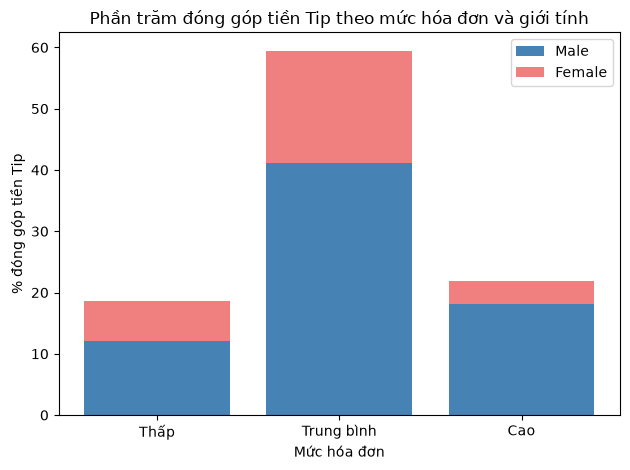

In [7]:
x = range(len(percent_by_group_sex.index))

plt.bar(x, percent_by_group_sex['Male'], label='Male', color='steelblue')
plt.bar(x, percent_by_group_sex['Female'], bottom=percent_by_group_sex['Male'], label='Female', color='lightcoral')

plt.xticks(x, percent_by_group_sex.index)
plt.xlabel('Mức hóa đơn')
plt.ylabel('% đóng góp tiền Tip')
plt.title('Phần trăm đóng góp tiền Tip theo mức hóa đơn và giới tính')
plt.legend()
plt.tight_layout()
plt.show()